# ST-GNN spatial ablations — Infiltration, original labels

Trains **ST Uniform** (two message-passing layers with equal weights for incoming messages) and **ST No Message** (two nodewise transformations without inter-node messages). Both retain the incoming/outgoing feature construction, per-node GRU, and classifier of `ST_GNN_Identity`. The first variant tests learned weighting against uniform aggregation; the second tests neighbor propagation. `Edge GRU` remains an independent baseline, not an identical ablation.

**Original training protocol:** seeds `42, 123, 777, 2024, 99`; at most 60 epochs; Adam with learning rate 0.005; `pos_weight=2`; TBPTT over 10 windows; patience 10 based on validation AP; validation max-F1 threshold; champion chosen by the one-standard-deviation rule on validation F1 and earliest stopping epoch. Test 1 evaluates all five seeds; Test 2 evaluates only the validation-selected champion. Original graphs and labels are used, with no MITRE mapping.

Run cells in order in Colab with a GPU. New results are stored in a separate Drive directory after each completed seed. Rerunning the training cell verifies and skips completed seeds; an interrupted seed starts again. `results_earlystopping` is not modified. Comparisons with the five original models read CSVs already audited by checkpoint inference. If all ten seed records are complete, rerunning the training cell does **not** retrain them.


In [1]:
import importlib.util, subprocess, sys
from pathlib import Path

if importlib.util.find_spec('torch_geometric') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'torch_geometric'], check=True)

from google.colab import drive
drive.mount('/content/drive')

DRIVE_ROOT = Path('/content/drive/MyDrive/nids-mitre')
CLONE_DIR = Path('/content/temporalgnn-nids-st-ablation')
SOURCE_BRANCH = 'feat/fair-comparison-experiments'
SOURCE_COMMIT = '2262b53d155f9e8cf5221516f47e4170e6cd0d6e'
if not CLONE_DIR.exists():
    subprocess.run(['git', 'clone', '--depth', '1', '--branch', SOURCE_BRANCH,
                    'https://github.com/tatipar/temporalgnn-nids.git', str(CLONE_DIR)], check=True)
subprocess.run(
    ['git', '-C', str(CLONE_DIR), 'fetch', '--depth', '1', 'origin', SOURCE_COMMIT],
    check=True,
)
subprocess.run(
    ['git', '-C', str(CLONE_DIR), 'checkout', '--detach', SOURCE_COMMIT],
    check=True,
)
actual_commit = subprocess.check_output(
    ['git', '-C', str(CLONE_DIR), 'rev-parse', 'HEAD'], text=True
).strip()
assert actual_commit == SOURCE_COMMIT, (
    f'Code commit changed: {actual_commit}; expected {SOURCE_COMMIT}'
)
sys.path.insert(0, str(CLONE_DIR / 'code/python'))
print('Pinned code:', actual_commit)

Mounted at /content/drive
Pinned code: 2262b53d155f9e8cf5221516f47e4170e6cd0d6e


In [2]:
import gc, hashlib, json, os, platform
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch_geometric
from sklearn.metrics import average_precision_score
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GATv2Conv
from torch_geometric.utils import softmax as pyg_softmax
from IPython.display import display

from utils.datasets import NF_IDS_Dataset
from utils.models import ST_GNN_Identity
from utils.training import train_epoch, evaluate, find_optimal_threshold, set_seed
from utils.experiment import EarlyStopping, NumpyEncoder
from utils.metrics import calculate_metrics_gnn
from utils.evaluation import apply_1sd_rule

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEEDS = [42, 123, 777, 2024, 99]
PARAMS = dict(node_dim=16, edge_dim=32, hidden_dim=32,
              dropout=0.2, output_bias_init=-2.9968)
TRAINING = dict(epochs=60, batch_steps=10, learning_rate=0.005,
                pos_weight=2.0, patience=10, min_delta=0.0001)

DAY1_ROOT = DRIVE_ROOT / 'dataset_processed'
DAY2_ROOT = DRIVE_ROOT / 'dataset_processed_thu0103'
ORIGINAL_RESULTS = DRIVE_ROOT / 'results_earlystopping'
OUTPUT = DRIVE_ROOT / 'results_stgnn_spatial_ablation_v1'
for path in [DAY1_ROOT / 'train', DAY1_ROOT / 'val', DAY1_ROOT / 'test',
             DAY2_ROOT / 'test2', ORIGINAL_RESULTS]:
    assert path.is_dir(), f'Missing: {path}'

train_data = NF_IDS_Dataset(root_dir=str(DAY1_ROOT), split='train')
val_data = NF_IDS_Dataset(root_dir=str(DAY1_ROOT), split='val')
test1_data = NF_IDS_Dataset(root_dir=str(DAY1_ROOT), split='test')
test2_data = NF_IDS_Dataset(root_dir=str(DAY2_ROOT), split='test2')
assert len(test1_data) == 429, f'Test 1: expected 429 graphs; found {len(test1_data)}'
assert len(test2_data) == 2822, f'Test 2: expected 2,822 graphs; found {len(test2_data)}'

# Temporal order and batch_size=1 are required for per-node memory.
loader_opts = dict(batch_size=1, shuffle=False, num_workers=2,
                   persistent_workers=True, pin_memory=False)
train_loader = DataLoader(train_data, **loader_opts)
val_loader = DataLoader(val_data, **loader_opts)
test1_loader = DataLoader(test1_data, **loader_opts)
test2_loader = DataLoader(test2_data, **loader_opts)

manifest = dict(notebook_version=1, source_branch=SOURCE_BRANCH,
                source_commit=SOURCE_COMMIT, graph_train=str(DAY1_ROOT / 'train'),
                graph_val=str(DAY1_ROOT / 'val'), graph_test1=str(DAY1_ROOT / 'test'),
                graph_test2=str(DAY2_ROOT / 'test2'), seeds=SEEDS,
                model_params=PARAMS, training=TRAINING,
                labels='original', champion_rule='validation_F1_1SD_then_min_best_epoch')
OUTPUT.mkdir(parents=True, exist_ok=True)
manifest_path = OUTPUT / 'manifest.json'
if manifest_path.exists():
    assert json.loads(manifest_path.read_text()) == manifest, (
        'Output directory has a different configuration: ' + str(OUTPUT)
    )
else:
    manifest_path.write_text(json.dumps(manifest, indent=2))

print('Device:', DEVICE, '| GPU:', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'none')
print('PyTorch:', torch.__version__, '| PyG:', torch_geometric.__version__)
print('Graphs: train', len(train_data), '| val', len(val_data),
      '| test1', len(test1_data), '| test2', len(test2_data))
print('New results:', OUTPUT)

Device: cpu | GPU: none
PyTorch: 2.11.0+cpu | PyG: 2.8.1
Graphs: train 1998 | val 428 | test1 429 | test2 2822
New results: /content/drive/MyDrive/nids-mitre/results_stgnn_spatial_ablation_v1


## 1. Controlled variants

`UniformGATv2Conv` retains GATv2 transformations and connections, including self-loops, but assigns weight `1/k` to every incoming message at a node. In that layer, `edge_attr` no longer determines message weight; it still enters node-feature construction and the final classifier. `STNoMessage` replaces both propagation layers with independent nodewise transformations. Both variants are trained from scratch on their first run.


In [3]:
class UniformGATv2Conv(GATv2Conv):
    def edge_update(self, x_j, x_i, edge_attr, index, ptr, dim_size):
        zeros = x_j.new_zeros((x_j.size(0), self.heads))
        return pyg_softmax(zeros, index, ptr, dim_size)


class NodewiseLinear(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.linear = nn.Linear(in_dim, out_dim)

    def forward(self, x, edge_index, edge_attr=None):
        return self.linear(x)


class STUniform(ST_GNN_Identity):
    def __init__(self, node_dim, edge_dim, hidden_dim, dropout=0.2,
                 output_bias_init=None):
        super().__init__(node_dim, edge_dim, hidden_dim, dropout, output_bias_init)
        first = UniformGATv2Conv(2 * node_dim, hidden_dim, edge_dim=edge_dim,
                                 heads=2, concat=False, dropout=dropout)
        second = UniformGATv2Conv(hidden_dim, hidden_dim, edge_dim=edge_dim,
                                  heads=1, concat=False, dropout=dropout)
        # Preserve initialization of the base-class transformations.
        first.load_state_dict(self.gnn1.state_dict(), strict=True)
        second.load_state_dict(self.gnn2.state_dict(), strict=True)
        self.gnn1, self.gnn2 = first, second
        for layer in (self.gnn1, self.gnn2):
            for name, param in layer.named_parameters():
                if name == 'att' or name.startswith(('lin_r.', 'lin_edge.')):
                    param.requires_grad_(False)  # inactive under uniform weighting


class STNoMessage(ST_GNN_Identity):
    def __init__(self, node_dim, edge_dim, hidden_dim, dropout=0.2,
                 output_bias_init=None):
        super().__init__(node_dim, edge_dim, hidden_dim, dropout, output_bias_init)
        self.gnn1 = NodewiseLinear(2 * node_dim, hidden_dim)
        self.gnn2 = NodewiseLinear(hidden_dim, hidden_dim)


VARIANTS = {'ST Uniform': STUniform, 'ST No Message': STNoMessage}
for name, cls in VARIANTS.items():
    set_seed(42)
    model = cls(**PARAMS)
    print(name, '| trainable parameters:',
          sum(p.numel() for p in model.parameters() if p.requires_grad))
    del model

ST Uniform | trainable parameters: 13873
ST No Message | trainable parameters: 12753


## 2. Training and validation across five seeds

This cell can take time when seed records are missing. After **each completed seed**, it saves the checkpoint, training history, best epoch, validation metrics, and max-F1 threshold. On rerun, it verifies and skips completed seeds; an interrupted seed is trained again from the beginning. Champion selection happens later using validation only.


In [4]:
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


def record_paths(variant, seed):
    stem = variant.lower().replace(' ', '_')
    folder = OUTPUT / stem / f'seed_{seed}'
    return folder, folder / 'checkpoint.pth', folder / 'record.json'


def read_record(variant, seed):
    _, checkpoint, record_path = record_paths(variant, seed)
    if not (checkpoint.exists() and record_path.exists()):
        return None
    record = json.loads(record_path.read_text())
    assert record['variant'] == variant and record['seed'] == seed
    assert record['source_commit'] == SOURCE_COMMIT
    assert record['checkpoint_sha256'] == sha256_file(checkpoint), (
        f'Modified or incomplete checkpoint: {checkpoint}'
    )
    return record


def train_one(variant, seed):
    previous = read_record(variant, seed)
    if previous is not None:
        print(f'{variant}, seed {seed}: already complete; skipping')
        return previous

    folder, checkpoint, record_path = record_paths(variant, seed)
    folder.mkdir(parents=True, exist_ok=True)
    set_seed(seed)
    model = VARIANTS[variant](**PARAMS).to(DEVICE)
    optimizer = torch.optim.Adam(
        (p for p in model.parameters() if p.requires_grad),
        lr=TRAINING['learning_rate']
    )
    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor([TRAINING['pos_weight']], device=DEVICE)
    )
    stopper = EarlyStopping(patience=TRAINING['patience'],
                            min_delta=TRAINING['min_delta'], mode='max')
    history = []
    print(f'Training {variant}, seed {seed}')
    for epoch in range(TRAINING['epochs']):
        train_loss = train_epoch(
            model, train_loader, optimizer, criterion, DEVICE,
            is_temporal=True, batch_steps=TRAINING['batch_steps']
        )
        val_loss, val_y, val_p = evaluate(
            model, val_loader, criterion, DEVICE, is_temporal=True
        )
        val_ap = float(average_precision_score(val_y, val_p))
        assert np.isfinite(val_ap), f'Invalid AP for {variant}, seed {seed}'
        improved = stopper(val_ap, model, epoch)
        history.append(dict(epoch=epoch + 1, train_loss=float(train_loss),
                            val_loss=float(val_loss), val_ap=val_ap))
        if improved or (epoch + 1) % 10 == 0:
            print(f'  epoch {epoch + 1}: train loss={train_loss:.4f}, '
                  f'val AP={val_ap:.4f}' + (' *' if improved else ''))
        if stopper.early_stop:
            print('  early stopping at epoch', epoch + 1)
            break

    assert stopper.best_model_state is not None
    model.load_state_dict(stopper.best_model_state, strict=True)
    threshold, val_y, val_p = find_optimal_threshold(
        model, val_loader, DEVICE, is_temporal=True, strategy='max_f1'
    )
    val_metrics = calculate_metrics_gnn(val_y, val_p,
                                        prob_threshold=float(threshold))
    record = dict(variant=variant, seed=seed,
                  run_id=f'{variant.lower().replace(" ", "_")}_seed{seed}',
                  source_commit=SOURCE_COMMIT,
                  best_epoch=int(stopper.best_epoch),  # same zero-based convention as the project
                  stopped_epoch=len(history),
                  best_val_ap=float(stopper.best_score),
                  threshold=float(threshold), val_metrics=val_metrics,
                  history=history,
                  torch_version=torch.__version__,
                  pyg_version=torch_geometric.__version__)

    # The JSON marks a completed seed; write it last.
    tmp_checkpoint = folder / 'checkpoint.pth.tmp'
    torch.save(model.state_dict(), tmp_checkpoint)
    os.replace(tmp_checkpoint, checkpoint)
    record['checkpoint_sha256'] = sha256_file(checkpoint)
    tmp_record = folder / 'record.json.tmp'
    tmp_record.write_text(json.dumps(record, cls=NumpyEncoder, indent=2))
    os.replace(tmp_record, record_path)
    print(f'  complete: best epoch={record["best_epoch"] + 1}, '
          f'val AP={val_metrics["AUC-PR"]:.4f}, '
          f'val F1={val_metrics["F1"]:.4f}, '
          f'threshold={float(threshold):.6f}')
    del model, optimizer, criterion, stopper
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return record


for variant in VARIANTS:
    for seed in SEEDS:
        train_one(variant, seed)
print('All ten model-seed combinations are complete.')

ST Uniform, seed 42: already complete; skipping
ST Uniform, seed 123: already complete; skipping
ST Uniform, seed 777: already complete; skipping
ST Uniform, seed 2024: already complete; skipping
ST Uniform, seed 99: already complete; skipping
ST No Message, seed 42: already complete; skipping
ST No Message, seed 123: already complete; skipping
ST No Message, seed 777: already complete; skipping
ST No Message, seed 2024: already complete; skipping
ST No Message, seed 99: already complete; skipping
All ten model-seed combinations are complete.


## 3. Champions selected by validation only

Uses `apply_1sd_rule()` from the same commit as the original evaluation. Among seeds within one standard deviation of the maximum validation F1, it selects the earliest `best_epoch`; ties favor higher F1. Neither Test 1 nor Test 2 enters champion selection.


In [5]:
validation_rows = []
for variant in VARIANTS:
    for seed in SEEDS:
        record = read_record(variant, seed)
        assert record is not None, f'Missing {variant}, seed {seed}'
        validation_rows.append({
            'Architecture': variant,
            'Raw_Dir_Name': variant,
            'Seed': seed,
            'F1_Score': record['val_metrics']['F1'],
            'Best_Epoch': record['best_epoch'],
            'Optimal_Threshold': record['threshold'],
            'Val_AUC-PR': record['val_metrics']['AUC-PR'],
        })
validation = pd.DataFrame(validation_rows)
champions = apply_1sd_rule(validation)
assert len(champions) == len(VARIANTS)
champion_seeds = dict(zip(champions['Architecture'],
                          champions['Seed'].astype(int)))
validation.to_csv(OUTPUT / 'validation_all_seeds.csv', index=False)
champions.to_csv(OUTPUT / 'champions_by_validation.csv', index=False)
print('Selected seeds:', champion_seeds)
display(validation.sort_values(['Architecture', 'Seed']).round(4))

                       SELECTION OF CHAMPIONS (RULE 1-SD)                       

Architecture: ST UNIFORM (Seeds analyzed: 5)
  -> F1 Range   : Max = 0.7825 | Std = 0.2447
  -> Zone 1-SD  : Models with F1 >= 0.5378
  -> Candidates : 4 seed(s) entered the safe zone.
     CHAMPION   : Seed 42 | F1: 0.7792 | Training epochs: 17

Architecture: ST NO MESSAGE (Seeds analyzed: 5)
  -> F1 Range   : Max = 0.7831 | Std = 0.0270
  -> Zone 1-SD  : Models with F1 >= 0.7561
  -> Candidates : 2 seed(s) entered the safe zone.
     CHAMPION   : Seed 2024 | F1: 0.7831 | Training epochs: 23
Selected seeds: {'ST Uniform': 42, 'ST No Message': 2024}


,Architecture,Raw_Dir_Name,Seed,F1_Score,Best_Epoch,Optimal_Threshold,Val_AUC-PR
5,ST No Message,ST No Message,42,0.7160,18,0.8890,0.7132
9,ST No Message,ST No Message,99,0.7394,43,0.2144,0.7723
6,ST No Message,ST No Message,123,0.7702,30,0.3268,0.7396
7,ST No Message,ST No Message,777,0.7381,28,0.2158,0.7147
8,ST No Message,ST No Message,2024,0.7831,23,0.6668,0.7428
0,ST Uniform,ST Uniform,42,0.7792,17,0.3789,0.7804
4,ST Uniform,ST Uniform,99,0.7784,32,0.3409,0.7645
1,ST Uniform,ST Uniform,123,0.2314,0,0.1200,0.2114
2,ST Uniform,ST Uniform,777,0.7741,25,0.3163,0.7897
3,ST Uniform,ST Uniform,2024,0.7825,25,0.3461,0.7899


## 4. Test 1: all five seeds of each variant

Evaluates frozen checkpoints at their validation thresholds. Each completed row is saved to support resuming. Uses the original `evaluate()` and `calculate_metrics_gnn()`, including the strict `probability > threshold` decision rule.


In [6]:
def evaluate_new(tag, variant, seed):
    assert tag in ('test1', 'test2')
    record = read_record(variant, seed)
    assert record is not None
    folder, checkpoint, _ = record_paths(variant, seed)
    cache = folder / f'{tag}_metrics.json'
    if cache.exists():
        row = json.loads(cache.read_text())
        assert row['checkpoint_sha256'] == record['checkpoint_sha256']
        assert row['threshold'] == record['threshold']
        print(f'{tag}: {variant}, seed {seed}: already evaluated')
        return row

    model = VARIANTS[variant](**PARAMS).to(DEVICE)
    model.load_state_dict(torch.load(checkpoint, map_location=DEVICE,
                                     weights_only=True), strict=True)
    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor([TRAINING['pos_weight']], device=DEVICE)
    )
    loader = test1_loader if tag == 'test1' else test2_loader
    _, labels, probabilities = evaluate(
        model, loader, criterion, DEVICE, is_temporal=True
    )
    if tag == 'test2':
        assert len(labels) == 2_135_957, (
            f'Test 2 should have 2,135,957 flows; found {len(labels)}'
        )
    metrics = calculate_metrics_gnn(
        labels, probabilities, prob_threshold=record['threshold']
    )
    row = dict(test=tag, model=variant, seed=seed,
               run_id=record['run_id'],
               threshold=record['threshold'],
               flows=len(labels), attacks=int(labels.sum()),
               checkpoint_sha256=record['checkpoint_sha256'], **metrics)
    tmp = folder / f'{tag}_metrics.json.tmp'
    tmp.write_text(json.dumps(row, cls=NumpyEncoder, indent=2))
    os.replace(tmp, cache)
    print(f'{tag}: {variant}, seed {seed}: '
          f'AP={metrics["AUC-PR"]:.4f}, F1={metrics["F1"]:.4f}')
    del model, criterion
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return row


new_t1 = pd.DataFrame([
    evaluate_new('test1', variant, seed)
    for variant in VARIANTS for seed in SEEDS
])
assert len(new_t1) == 10
assert new_t1['flows'].nunique() == new_t1['attacks'].nunique() == 1
new_t1.to_csv(OUTPUT / 'test1_all_seeds.csv', index=False)
display(new_t1[['model', 'seed', 'flows', 'attacks',
                'AUC-PR', 'F1', 'Precision', 'Recall', 'FPR']].round(4))

test1: ST Uniform, seed 42: already evaluated
test1: ST Uniform, seed 123: already evaluated
test1: ST Uniform, seed 777: already evaluated
test1: ST Uniform, seed 2024: already evaluated
test1: ST Uniform, seed 99: already evaluated
test1: ST No Message, seed 42: already evaluated
test1: ST No Message, seed 123: already evaluated
test1: ST No Message, seed 777: already evaluated
test1: ST No Message, seed 2024: already evaluated
test1: ST No Message, seed 99: already evaluated


,model,seed,flows,attacks,AUC-PR,F1,Precision,Recall,FPR
0,ST Uniform,42,191679,3434,0.6923,0.7218,0.6835,0.7647,0.0065
1,ST Uniform,123,191679,3434,0.1016,0.0192,0.0869,0.0108,0.0021
2,ST Uniform,777,191679,3434,0.6304,0.7267,0.7437,0.7105,0.0045
3,ST Uniform,2024,191679,3434,0.7029,0.7400,0.7169,0.7647,0.0055
4,ST Uniform,99,191679,3434,0.6519,0.7031,0.6521,0.7627,0.0074
5,ST No Message,42,191679,3434,0.7014,0.7494,0.8097,0.6974,0.0030
6,ST No Message,123,191679,3434,0.6879,0.6712,0.5779,0.8005,0.0107
7,ST No Message,777,191679,3434,0.6978,0.7152,0.6473,0.7991,0.0079
8,ST No Message,2024,191679,3434,0.6897,0.7319,0.7035,0.7627,0.0059
9,ST No Message,99,191679,3434,0.6744,0.7058,0.6915,0.7207,0.0059


## 5. Test 2: validation-selected champions only

Validation has already fixed checkpoints and thresholds. Each variant is evaluated once on the 2,135,957 Test 2 flows; the best seed is not selected using Test 2.


In [7]:
new_t2 = pd.DataFrame([
    evaluate_new('test2', variant, champion_seeds[variant])
    for variant in VARIANTS
])
assert len(new_t2) == 2
new_t2.to_csv(OUTPUT / 'test2_champions.csv', index=False)
display(new_t2[['model', 'seed', 'flows', 'attacks',
                'AUC-PR', 'F1', 'Precision', 'Recall', 'FPR', 'TP', 'FP']].round(4))

test2: ST Uniform, seed 42: already evaluated
test2: ST No Message, seed 2024: already evaluated


,model,seed,flows,attacks,AUC-PR,F1,Precision,Recall,FPR,TP,FP
0,ST Uniform,42,2135957,103825,0.6883,0.6256,0.566,0.6993,0.0274,72609,55676
1,ST No Message,2024,2135957,103825,0.6601,0.7115,0.761,0.6681,0.0107,69362,21788


## 6. Comparison with audited original models

Reads the audited original CSVs for Test 1 (five seeds) and Test 2 (one champion per architecture). New results are joined only if flow and attack counts match. Test 1 reports mean and standard deviation across seeds; Test 2 reports each champion. Paired same-seed differences against ST-GNN and Edge GRU are also shown for Test 1.


In [8]:
ORIGINAL_MODELS = {
    'Simple MLP': 'SimpleMLP_BiasOn',
    'E-GraphSAGE': 'EGraphSAGE_BiasOn',
    'Edge GRU': 'EdgeGRU_NoX_BiasOn',
    'Static GNN': 'StaticGNN_BiasOn_robust_Identity',
    'ST-GNN': 'ST_GNN_BiasOn_robust_Identity_clone',
}

def original_rows(tag):
    parts = []
    for display_name, experiment in ORIGINAL_MODELS.items():
        if tag == 'test1':
            path = ORIGINAL_RESULTS / 'test1_results' / f'test1_metrics_{experiment}.csv'
            expected_rows = 5
        else:
            path = ORIGINAL_RESULTS / 'test2_results' / f'test2_metrics_{experiment}.csv'
            expected_rows = 1
        frame = pd.read_csv(path)
        assert len(frame) == expected_rows, f'Unexpected row count: {path}'
        assert frame['run_id'].notna().all(), f'Missing run_id: {path}'
        assert frame['run_id'].is_unique, f'Duplicate run_id: {path}'
        if tag == 'test1':
            assert set(frame['seed'].astype(int)) == set(SEEDS), path
        frame['model'] = display_name
        frame['seed'] = frame['seed'].astype(int)
        frame['flows'] = frame[['TP', 'FP', 'TN', 'FN']].sum(axis=1).astype(int)
        frame['attacks'] = (frame['TP'] + frame['FN']).astype(int)
        parts.append(frame)
    return pd.concat(parts, ignore_index=True)

orig_t1 = original_rows('test1')
orig_t2 = original_rows('test2')
assert orig_t1['flows'].nunique() == orig_t1['attacks'].nunique() == 1
assert orig_t2['flows'].nunique() == orig_t2['attacks'].nunique() == 1
assert int(orig_t1['flows'].iloc[0]) == int(new_t1['flows'].iloc[0])
assert int(orig_t1['attacks'].iloc[0]) == int(new_t1['attacks'].iloc[0])
assert int(orig_t2['flows'].iloc[0]) == int(new_t2['flows'].iloc[0])
assert int(orig_t2['attacks'].iloc[0]) == int(new_t2['attacks'].iloc[0])

columns = ['model', 'seed', 'flows', 'attacks', 'AUC-PR', 'F1',
           'Precision', 'Recall', 'FPR', 'TP', 'FP']
all_t1 = pd.concat([orig_t1[columns], new_t1[columns]], ignore_index=True)
all_t2 = pd.concat([orig_t2[columns], new_t2[columns]], ignore_index=True)
order = list(ORIGINAL_MODELS) + list(VARIANTS)
all_t1['model'] = pd.Categorical(all_t1['model'], categories=order, ordered=True)
all_t2['model'] = pd.Categorical(all_t2['model'], categories=order, ordered=True)
all_t1 = all_t1.sort_values(['model', 'seed'])
all_t2 = all_t2.sort_values('model')
all_t1.to_csv(OUTPUT / 'comparison_test1_all_seeds.csv', index=False)
all_t2.to_csv(OUTPUT / 'comparison_test2_champions.csv', index=False)

summary_t1 = all_t1.groupby('model', observed=True).agg(
    AP_mean=('AUC-PR', 'mean'), AP_std=('AUC-PR', 'std'),
    F1_mean=('F1', 'mean'), F1_std=('F1', 'std'),
    Recall_mean=('Recall', 'mean'), FPR_mean=('FPR', 'mean'),
    seeds=('seed', 'count')
).reset_index()
summary_t1.to_csv(OUTPUT / 'comparison_test1_summary.csv', index=False)
print('TEST 1 — five seeds:')
display(summary_t1.round(4))
print('TEST 2 — validation-selected champion:')
display(all_t2[['model', 'seed', 'AUC-PR', 'F1', 'Precision',
                'Recall', 'FPR', 'TP', 'FP']].round(4))

paired_rows = []
for variant in VARIANTS:
    for reference in ['ST-GNN', 'Edge GRU']:
        left = all_t1.loc[all_t1['model'] == variant,
                          ['seed', 'AUC-PR', 'F1']]
        right = all_t1.loc[all_t1['model'] == reference,
                           ['seed', 'AUC-PR', 'F1']]
        pair = left.merge(right, on='seed', suffixes=('_new', '_reference'),
                          validate='one_to_one')
        assert len(pair) == 5
        for _, row in pair.iterrows():
            paired_rows.append(dict(variant=variant, reference=reference,
                                    seed=int(row['seed']),
                                    AP_difference=row['AUC-PR_new'] - row['AUC-PR_reference'],
                                    F1_difference=row['F1_new'] - row['F1_reference']))
paired = pd.DataFrame(paired_rows)
paired.to_csv(OUTPUT / 'comparison_test1_paired_differences.csv', index=False)
print('Same-seed differences on Test 1 (variant minus reference):')
display(paired.round(4))
print('Comparison files:', OUTPUT)

TEST 1 — five seeds:


,model,AP_mean,AP_std,F1_mean,F1_std,Recall_mean,FPR_mean,seeds
0,Simple MLP,0.0510,0.0078,0.0012,0.0017,0.0008,0.0024,5
1,E-GraphSAGE,0.3306,0.0185,0.4839,0.0198,0.6872,0.0212,5
2,Edge GRU,0.5143,0.2452,0.4289,0.1745,0.7116,0.0399,5
3,Static GNN,0.4257,0.0423,0.5674,0.0719,0.6944,0.0147,5
4,ST-GNN,0.6710,0.0156,0.7041,0.0319,0.7284,0.0062,5
5,ST Uniform,0.5558,0.2556,0.5822,0.3150,0.6027,0.0052,5
6,ST No Message,0.6902,0.0105,0.7147,0.0294,0.7561,0.0067,5


TEST 2 — validation-selected champion:


,model,seed,AUC-PR,F1,Precision,Recall,FPR,TP,FP
0,Simple MLP,777,0.3961,0.4722,0.8805,0.3226,0.0022,33492,4547
1,E-GraphSAGE,99,0.5050,0.4950,0.5787,0.4324,0.0161,44891,32677
2,Edge GRU,99,0.7307,0.6502,0.5990,0.7110,0.0243,73819,49410
3,Static GNN,42,0.3142,0.2944,0.5094,0.2071,0.0102,21497,20707
4,ST-GNN,42,0.8384,0.7576,0.6336,0.9419,0.0278,97793,56546
5,ST Uniform,42,0.6883,0.6256,0.5660,0.6993,0.0274,72609,55676
6,ST No Message,2024,0.6601,0.7115,0.7610,0.6681,0.0107,69362,21788


Same-seed differences on Test 1 (variant minus reference):


,variant,reference,seed,AP_difference,F1_difference
0,ST Uniform,ST-GNN,42,0.0210,0.0139
1,ST Uniform,ST-GNN,99,-0.0368,0.0296
2,ST Uniform,ST-GNN,123,-0.5476,-0.6502
3,ST Uniform,ST-GNN,777,-0.0520,-0.0092
4,ST Uniform,ST-GNN,2024,0.0392,0.0061
5,ST Uniform,Edge GRU,42,0.0606,0.2266
6,ST Uniform,Edge GRU,99,-0.0651,0.1320
7,ST Uniform,Edge GRU,123,-0.0604,-0.1670
8,ST Uniform,Edge GRU,777,-0.0746,0.1434
9,ST Uniform,Edge GRU,2024,0.3468,0.4315


Comparison files: /content/drive/MyDrive/nids-mitre/results_stgnn_spatial_ablation_v1


## Methodological interpretation

- **ST Uniform vs. ST-GNN:** retrained models with and without adaptive message attention, retaining graph connections and the GRU. `edge_attr` contributes to attention in the original GAT; uniform weighting removes that contribution to attention, while leaving it in node attributes and the classifier.
- **ST Uniform vs. ST No Message:** tests neighbor-representation propagation with the rest of the ST design retained. The architectures have different numbers of active parameters, which the notebook reports.
- **ST No Message vs. Edge GRU:** both are temporal models without GAT propagation, but use different input summaries and classifiers. Their difference cannot be assigned to a single component.
- **Test 2:** one champion per architecture. Gains concentrated in a few sources require further analysis before generalization. No variant evaluates attack stages or chains.


## Complementary Analysis






### 1. Check seed 123

In [9]:
# Validation summary for all ST Uniform seeds.
uniform_rows = []
for seed in SEEDS:
    record = read_record("ST Uniform", seed)
    assert record is not None, f"ST Uniform Missing, seed {seed}"
    history = pd.DataFrame(record["history"])

    uniform_rows.append({
        "seed": seed,
        "best_epoch_shown": record["best_epoch"] + 1,
        "stopped_epoch": record["stopped_epoch"],
        "AP_val_first_epoch": history["val_ap"].iloc[0],
        "AP_val_best_checkpoint": record["best_val_ap"],
        "AP_val_last_epoch": history["val_ap"].iloc[-1],
        "F1_val_best_checkpoint": record["val_metrics"]["F1"],
        "threshold_validation": record["threshold"],
    })

display(pd.DataFrame(uniform_rows).sort_values("seed").round(4))

print("Complete history of ST Uniform, seed 123:")
display(
    pd.DataFrame(read_record("ST Uniform", 123)["history"])
    [["epoch", "train_loss", "val_loss", "val_ap"]]
    .round(4)
)


,seed,best_epoch_shown,stopped_epoch,AP_val_first_epoch,AP_val_best_checkpoint,AP_val_last_epoch,F1_val_best_checkpoint,threshold_validation
0,42,18,28,0.1505,0.7804,0.7717,0.7792,0.3789
4,99,33,43,0.0460,0.7645,0.7222,0.7784,0.3409
1,123,1,11,0.2114,0.2114,0.1090,0.2314,0.1200
2,777,26,36,0.3615,0.7897,0.7656,0.7741,0.3163
3,2024,26,36,0.1776,0.7899,0.7647,0.7825,0.3461


Complete history of ST Uniform, seed 123:


,epoch,train_loss,val_loss,val_ap
0,1,0.2189,0.2333,0.2114
1,2,0.1651,0.2367,0.0644
2,3,0.1969,0.2318,0.0852
3,4,0.1856,0.2372,0.0858
4,5,0.1791,0.2440,0.0676
5,6,0.1710,0.2209,0.0931
6,7,0.1682,0.2213,0.1287
7,8,0.1487,0.2456,0.0872
8,9,0.1945,0.2092,0.1458
9,10,0.1522,0.2046,0.1985


### 2. Obtaining and saving the predictions of the three top-performing models in Test 2

This cell identifies the original ST-GNN checkpoint by its `run_id`, and those of the variants by their respective records. It saves the predictions to Drive, allowing for the repetition of analyses without the need to re-run inference.


In [10]:
from utils.models import ST_GNN_Identity

ABL_DIAG = OUTPUT / "diagnostic_test2_spatial"
ABL_DIAG.mkdir(parents=True, exist_ok=True)

# Original audited checkpoints and thresholds for ST-GNN.
original_exp = "ST_GNN_BiasOn_robust_Identity_clone"
original_csv = (
    ORIGINAL_RESULTS / "test2_results"
    / f"test2_metrics_{original_exp}.csv"
)
original_row = pd.read_csv(original_csv).iloc[0]
original_seed = int(original_row["seed"])
original_run_id = str(original_row["run_id"])
assert original_seed == 42

original_matches = list(
    (ORIGINAL_RESULTS / "saved_models" / original_exp)
    .glob(f"{original_run_id}_*.pth")
)
assert len(original_matches) == 1, original_matches
original_checkpoint = original_matches[0]

threshold_file = (
    ORIGINAL_RESULTS / "logs" / original_exp
    / f"thresholds_{original_exp}.npz"
)
with np.load(threshold_file) as saved_thresholds:
    original_threshold = float(
        saved_thresholds[f"seed_{original_seed}"]
    )

model_specs = {
    "ST-GNN": {
        "constructor": ST_GNN_Identity,
        "checkpoint": original_checkpoint,
        "seed": original_seed,
        "threshold": original_threshold,
    }
}

for variant in ("ST Uniform", "ST No Message"):
    seed = int(champion_seeds[variant])
    record = read_record(variant, seed)
    assert record is not None, (variant, seed)
    _, checkpoint_path, _ = record_paths(variant, seed)

    model_specs[variant] = {
        "constructor": VARIANTS[variant],
        "checkpoint": checkpoint_path,
        "seed": seed,
        "threshold": float(record["threshold"]),
    }

def predictions_test2(name, spec):
    """Temporal inference in order; searched by checkpoint and threshold."""
    cache_path = ABL_DIAG / (
        name.lower().replace(" ", "_").replace("-", "_")
        + f"_seed_{spec['seed']}.npz"
    )
    checkpoint_hash = sha256_file(spec["checkpoint"])

    if cache_path.exists():
        with np.load(cache_path, allow_pickle=False) as saved:
            assert str(saved["checkpoint_sha256"].item()) == checkpoint_hash
            assert float(saved["threshold"]) == spec["threshold"]
            labels = saved["labels"]
            sources = saved["sources"]
            probabilities = saved["probabilities"]
        print(f"{name}: Drive-loaded predictions")
    else:
        model = spec["constructor"](**PARAMS).to(DEVICE)
        state = torch.load(
            spec["checkpoint"], map_location=DEVICE, weights_only=True
        )
        model.load_state_dict(state, strict=True)
        model.eval()
        model.reset_memory()

        label_parts, source_parts, probability_parts = [], [], []

        with torch.no_grad():
            for window_number, data in enumerate(test2_loader, start=1):
                data = data.to(DEVICE)
                if data.x.shape[0] == 0:
                    continue

                logits = model(
                    data.x,
                    data.edge_index,
                    data.edge_attr,
                    data.global_node_ids,
                ).view(-1)

                label_parts.append(
                    data.y.detach().cpu().numpy().astype(np.int8)
                )
                source_parts.append(
                    data.global_node_ids[data.edge_index[0]]
                    .detach().cpu().numpy().astype(np.int64)
                )
                probability_parts.append(
                    torch.sigmoid(logits)
                    .detach().cpu().numpy().astype(np.float32)
                )

                if window_number % 500 == 0:
                    print(f"{name}: {window_number} processed windows")

        labels = np.concatenate(label_parts)
        sources = np.concatenate(source_parts)
        probabilities = np.concatenate(probability_parts)

        tmp_path = cache_path.with_name(cache_path.stem + ".tmp.npz")
        np.savez_compressed(
            tmp_path,
            labels=labels,
            sources=sources,
            probabilities=probabilities,
            checkpoint_sha256=np.array(checkpoint_hash),
            threshold=np.array(spec["threshold"]),
        )
        os.replace(tmp_path, cache_path)
        print(f"{name}: predictions saved in {cache_path}")

        del model, state
        gc.collect()
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    assert len(labels) == len(sources) == len(probabilities) == 2_135_957
    assert int(labels.sum()) == 103_825

    return {
        "labels": labels,
        "sources": sources,
        "probabilities": probabilities,
        "threshold": spec["threshold"],
    }

predictions = {
    name: predictions_test2(name, spec)
    for name, spec in model_specs.items()
}

reference_labels = predictions["ST-GNN"]["labels"]
reference_sources = predictions["ST-GNN"]["sources"]

for name, result in predictions.items():
    np.testing.assert_array_equal(result["labels"], reference_labels)
    np.testing.assert_array_equal(result["sources"], reference_sources)

main_source = reference_sources == 1195
assert int(main_source.sum()) == 51_625
assert int(reference_labels[main_source].sum()) == 36_934

# Control: the complete predictions must reproduce the results shown.
expected = {
    "ST-GNN": (0.8384, 0.7576),
    "ST Uniform": (0.6883, 0.6256),
    "ST No Message": (0.6601, 0.7115),
}

for name, result in predictions.items():
    metrics = calculate_metrics_gnn(
        result["labels"],
        result["probabilities"],
        prob_threshold=result["threshold"],
    )
    expected_ap, expected_f1 = expected[name]
    assert np.isclose(metrics["AUC-PR"], expected_ap, atol=0.0002), (
        name, "AP", metrics["AUC-PR"], expected_ap
    )
    assert np.isclose(metrics["F1"], expected_f1, atol=0.0002), (
        name, "F1", metrics["F1"], expected_f1
    )
    print(
        f"{name}: AP={metrics['AUC-PR']:.4f}, "
        f"F1={metrics['F1']:.4f}; reproduces Test 2"
    )


ST-GNN: Drive-loaded predictions
ST Uniform: Drive-loaded predictions
ST No Message: Drive-loaded predictions
ST-GNN: AP=0.8384, F1=0.7576; reproduces Test 2
ST Uniform: AP=0.6883, F1=0.6256; reproduces Test 2
ST No Message: AP=0.6601, F1=0.7115; reproduces Test 2


### 3. Compare by subset and with the same alert budget

The first table uses the original validation threshold for each model. The second compares the ordering of flows with exactly the same number of alerts.


In [11]:
subsets = {
    "Full Test 2": np.ones(len(reference_labels), dtype=bool),
    "Only source 1195": main_source,
    "Without source 1195": ~main_source,
}

# Metrics by subset, with thresholds set during validation.
subset_rows = []

for subset_name, mask in subsets.items():
    for name, result in predictions.items():
        labels = result["labels"][mask]
        probabilities = result["probabilities"][mask]
        metrics = calculate_metrics_gnn(
            labels,
            probabilities,
            prob_threshold=result["threshold"],
        )

        subset_rows.append({
            "subset_name": subset_name,
            "model": name,
            "flows": len(labels),
            "attacks": int(labels.sum()),
            "AP": metrics["AUC-PR"],
            "F1": metrics["F1"],
            "precision": metrics["Precision"],
            "recall": metrics["Recall"],
            "FPR": metrics["FPR"],
            "TP": metrics["TP"],
            "FP": metrics["FP"],
        })

subset_table = pd.DataFrame(subset_rows)
display(subset_table.round(4))
subset_table.to_csv(ABL_DIAG / "metrics_per_subset.csv", index=False)

# Top-K: the same number of alerts for each model within each subset.
budgets = {
    "Full Test 2": (10_000, 50_000, 100_000),
    "Only source 1195": (1_000, 10_000, 30_000),
    "Without source 1195": (10_000, 50_000, 100_000),
}
budget_rows = []

for subset_name, mask in subsets.items():
    subset_indices = np.flatnonzero(mask)
    total_attacks = int(reference_labels[mask].sum())

    for name, result in predictions.items():
        probabilities = result["probabilities"]

        # A stable ordering so that ties are resolved according to a reproducible criterion.
        ordered_indices = subset_indices[
            np.argsort(-probabilities[subset_indices], kind="stable")
        ]

        for requested_k in budgets[subset_name]:
            k = min(requested_k, len(ordered_indices))
            selected = ordered_indices[:k]
            selected_labels = reference_labels[selected]
            selected_main = reference_sources[selected] == 1195

            tp = int(selected_labels.sum())
            alerts_main = int(selected_main.sum())
            tp_main = int(selected_labels[selected_main].sum())

            budget_rows.append({
                "subset_name": subset_name,
                "model": name,
                "alerts": k,
                "detected_attacks": tp,
                "false_alarms": k - tp,
                "precision": tp / k,
                "recall": tp / total_attacks,
                "alerts_1195": alerts_main,
                "attacks_1195": tp_main,
                "false_alarms_1195": alerts_main - tp_main,
                "remaining_attacks": tp - tp_main,
            })

budget_table = pd.DataFrame(budget_rows)
display(budget_table.round(4))
budget_table.to_csv(ABL_DIAG / "same_budget_alerts.csv", index=False)

print("Tables and predictions saved in:", ABL_DIAG)


,subset_name,model,flows,attacks,AP,F1,precision,recall,FPR,TP,FP
0,Full Test 2,ST-GNN,2135957,103825,0.8384,0.7576,0.6336,0.9419,0.0278,97793,56546
1,Full Test 2,ST Uniform,2135957,103825,0.6883,0.6256,0.5660,0.6993,0.0274,72609,55676
2,Full Test 2,ST No Message,2135957,103825,0.6601,0.7115,0.7610,0.6681,0.0107,69362,21788
3,Only source 1195,ST-GNN,51625,36934,0.9973,0.9757,0.9995,0.9530,0.0012,35198,18
4,Only source 1195,ST Uniform,51625,36934,0.9930,0.4012,0.9989,0.2510,0.0007,9272,10
5,Only source 1195,ST No Message,51625,36934,0.9655,0.4853,0.9988,0.3205,0.0010,11839,14
6,Without source 1195,ST-GNN,2084332,66891,0.7495,0.6730,0.5255,0.9358,0.0280,62595,56528
7,Without source 1195,ST Uniform,2084332,66891,0.7520,0.6814,0.5322,0.9469,0.0276,63337,55666
8,Without source 1195,ST No Message,2084332,66891,0.7866,0.7870,0.7254,0.8600,0.0108,57523,21774


,subset_name,model,alerts,detected_attacks,false_alarms,precision,recall,alerts_1195,attacks_1195,false_alarms_1195,remaining_attacks
0,Full Test 2,ST-GNN,10000,9243,757,0.9243,0.0890,5596,5582,14,3661
1,Full Test 2,ST-GNN,50000,45010,4990,0.9002,0.4335,22593,22577,16,22433
2,Full Test 2,ST-GNN,100000,82182,17818,0.8218,0.7915,30025,30007,18,52175
3,Full Test 2,ST Uniform,10000,8867,1133,0.8867,0.0854,2160,2156,4,6711
4,Full Test 2,ST Uniform,50000,40718,9282,0.8144,0.3922,2678,2674,4,38044
5,Full Test 2,ST Uniform,100000,59616,40384,0.5962,0.5742,3399,3389,10,56227
6,Full Test 2,ST No Message,10000,8651,1349,0.8651,0.0833,151,151,0,8500
7,Full Test 2,ST No Message,50000,41398,8602,0.8280,0.3987,2932,2930,2,38468
8,Full Test 2,ST No Message,100000,74592,25408,0.7459,0.7184,15207,15193,14,59399
9,Only source 1195,ST-GNN,1000,994,6,0.9940,0.0269,1000,994,6,0


Tables and predictions saved in: /content/drive/MyDrive/nids-mitre/results_stgnn_spatial_ablation_v1/diagnostic_test2_spatial


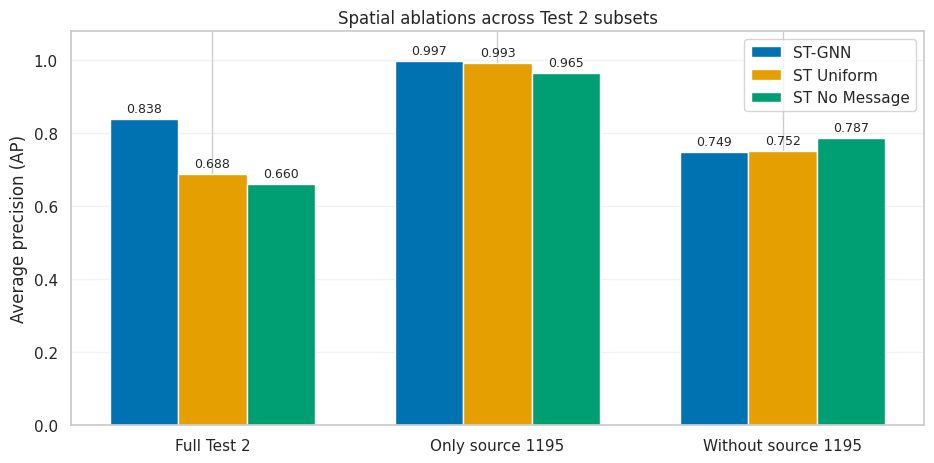

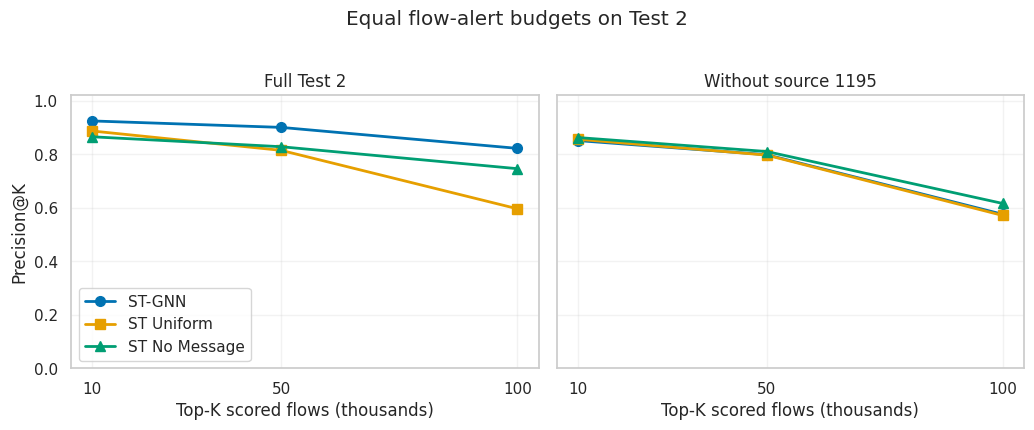

Figures saved in: /content/drive/MyDrive/nids-mitre/results_stgnn_spatial_ablation_v1/diagnostic_test2_spatial


In [15]:
import matplotlib.pyplot as plt

model_order = ["ST-GNN", "ST Uniform", "ST No Message"]
colors = {
    "ST-GNN": "#0072B2",
    "ST Uniform": "#E69F00",
    "ST No Message": "#009E73",
}
markers = {
    "ST-GNN": "o",
    "ST Uniform": "s",
    "ST No Message": "^",
}

# Figure 1: AP within each Test 2 subset.
subset_order = [
    "Full Test 2",
    "Only source 1195",
    "Without source 1195",
]
subset_labels = [
    "Full Test 2",
    "Only source 1195",
    "Without source 1195",
]

ap_table = subset_table.pivot(
    index="subset_name", columns="model", values="AP"
).loc[subset_order, model_order]

fig, ax = plt.subplots(figsize=(9.5, 4.8))
x = np.arange(len(subset_order))
bar_width = 0.24

for offset, model in zip([-1, 0, 1], model_order):
    bars = ax.bar(
        x + offset * bar_width,
        ap_table[model].to_numpy(),
        width=bar_width,
        label=model,
        color=colors[model],
    )
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)

ax.set_xticks(x, subset_labels)
ax.set_ylabel("Average precision (AP)")
ax.set_ylim(0, 1.08)
ax.set_title("Spatial ablations across Test 2 subsets")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=True, loc="upper right")

fig.tight_layout()
fig.savefig(ABL_DIAG / "spatial_ablation_ap_by_subset.pdf", bbox_inches="tight")
fig.savefig(
    ABL_DIAG / "spatial_ablation_ap_by_subset.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


# Figure 2: precision among the top-K scored flows.
# Each K is applied separately within the displayed subset.
plot_subsets = ["Full Test 2", "Without source 1195"]
budget_values = [10_000, 50_000, 100_000]

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), sharey=True)

for ax, subset_name in zip(axes, plot_subsets):
    precision_table = (
        budget_table.loc[budget_table["subset_name"] == subset_name]
        .pivot(index="alerts", columns="model", values="precision")
        .reindex(index=budget_values, columns=model_order)
    )
    assert not precision_table.isna().any().any(), (
        f"Missing precision@K results for {subset_name}"
    )

    for model in model_order:
        ax.plot(
            np.array(budget_values) / 1_000,
            precision_table[model].to_numpy(),
            label=model,
            color=colors[model],
            marker=markers[model],
            linewidth=2,
            markersize=7,
        )

    ax.set_title(subset_name)
    ax.set_xlabel("Top-K scored flows (thousands)")
    ax.set_xticks([10, 50, 100])
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.25)
    ax.set_axisbelow(True)

axes[0].set_ylabel("Precision@K")
axes[0].legend(frameon=True, loc="lower left")
fig.suptitle("Equal flow-alert budgets on Test 2", y=1.02)
fig.tight_layout()

fig.savefig(ABL_DIAG / "spatial_ablation_precision_at_k.pdf", bbox_inches="tight")
fig.savefig(
    ABL_DIAG / "spatial_ablation_precision_at_k.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("Figures saved in:", ABL_DIAG)